## 1. 데이터 불러오기

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 한글 지정
from matplotlib import font_manager, rc
font_path = "C:/Users/KDS22/data/malgun.ttf"   #폰트파일의 위치
font_name = font_manager.FontProperties(fname=font_path).get_name()
rc('font', family=font_name)

# 데이터를 뽑아서 변수에 저장
oecd_alchol_data = pd.read_csv('./data/project/OECD.ELS.HD,DSD_HEALTH_LVNG@DF_HEALTH_LVNG_AC,1.0+all.csv', sep = ",")
Drunk_driving = pd.read_excel('./data/project/가해자_음주정도별_교통사고.xlsx', sheet_name="데이터", engine="openpyxl")
soju_price = pd.read_excel('./data/project/생활물가지수_2020100__20260119154113.xlsx', sheet_name="데이터", engine="openpyxl", header = 1)

C:\Users\KDS22\anaconda3\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")
C:\Users\KDS22\anaconda3\Lib\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


### 1-1 데이터 항목 불러오고 결측치 제거

- ### 음주운전

In [ ]:
Drunk_driving.info() #음주운전 데이터의 각 항목의 columns명 확인

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 411 entries, 0 to 410
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   1당음주정도별(1)  3 non-null      object
 1   1당음주정도별(2)  13 non-null     object
 2   주야별(1)      26 non-null     object
 3   월별(1)       26 non-null     object
 4   시점          411 non-null    int64 
 5   사고건수 (건)    411 non-null    int64 
dtypes: int64(2), object(4)
memory usage: 19.4+ KB


In [ ]:
Drunk_driving

,1당음주정도별(1),1당음주정도별(2),주야별(1),월별(1),시점,사고건수 (건)
0,음주운전,0.03~0.049%,주,전체,2019,214
1,NaN,NaN,NaN,NaN,2020,365
2,NaN,NaN,NaN,NaN,2021,307
3,NaN,NaN,NaN,NaN,2022,328
4,NaN,NaN,NaN,NaN,2023,326
...,...,...,...,...,...,...
406,NaN,NaN,NaN,NaN,2020,70195
407,NaN,NaN,NaN,NaN,2021,65005
408,NaN,NaN,NaN,NaN,2022,62502
409,NaN,NaN,NaN,NaN,2023,62382


In [ ]:
#  피벗하여 묶여있어서 표시가 되지 않았던 데이터를 ffill데이터로 채워주기
group_cols = ["1당음주정도별(1)", "1당음주정도별(2)", "주야별(1)", "월별(1)"]
Drunk_driving[group_cols] = Drunk_driving[group_cols].ffill()
Drunk_driving

,1당음주정도별(1),1당음주정도별(2),주야별(1),월별(1),시점,사고건수 (건)
0,음주운전,0.03~0.049%,주,전체,2019,214
1,음주운전,0.03~0.049%,주,전체,2020,365
2,음주운전,0.03~0.049%,주,전체,2021,307
3,음주운전,0.03~0.049%,주,전체,2022,328
4,음주운전,0.03~0.049%,주,전체,2023,326
...,...,...,...,...,...,...
406,정상운전,정상운전,야,전체,2020,70195
407,정상운전,정상운전,야,전체,2021,65005
408,정상운전,정상운전,야,전체,2022,62502
409,정상운전,정상운전,야,전체,2023,62382


In [ ]:
# 정상운전은 음주와 관련없는 사고 데이터이기에 삭제
Drunk_driving = Drunk_driving.loc[Drunk_driving["1당음주정도별(1)"] != "정상운전"]

# 삭제하고 데이터를 csv로 저장
Drunk_driving.to_csv("./data/가해자_음주정도별_교통사고.csv", index=False, encoding="utf-8-sig")
Drunk_driving.head()

,1당음주정도별(1),1당음주정도별(2),주야별(1),월별(1),시점,사고건수 (건)
0,음주운전,0.03~0.049%,주,전체,2019,214
1,음주운전,0.03~0.049%,주,전체,2020,365
2,음주운전,0.03~0.049%,주,전체,2021,307
3,음주운전,0.03~0.049%,주,전체,2022,328
4,음주운전,0.03~0.049%,주,전체,2023,326


In [ ]:
# 연도별 데이터를 만들기 위해 빈 리스트를 만들고
# for 반복문으로 집어넣기 분류해서 집어넣기
# 그리고 집어넣은 데이터의 사고건수만 합하여 리스트로 만들어 놓고

Drunk_driving_year = {}
for i in range(2005, 2025):
    Drunk_driving_year[i] = Drunk_driving.loc[Drunk_driving["시점"] == i]

    Drunk_driving_sum = {}
for i in range(2005, 2025):
    Drunk_driving_sum[i] = Drunk_driving.loc[Drunk_driving["시점"] == i]["사고건수 (건)"].sum()

In [ ]:
# 데이터 프레임 화 하여 산출
total_Drunk = pd.DataFrame(list(Drunk_driving_sum.items()),
                           columns=["연도", "사고건수_총합"]).sort_values("연도").reset_index(drop=True)
total_Drunk.head()

,연도,사고건수_총합
0,2005,26473
1,2006,30185
2,2007,28662
3,2008,27009
4,2009,28394


- ### 술 소비량

In [ ]:
oecd_alchol_data.info() # 술 소비량의 인덱스 항목 확인

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2995 entries, 0 to 2994
Data columns (total 28 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   STRUCTURE                 2995 non-null   object 
 1   STRUCTURE_ID              2995 non-null   object 
 2   STRUCTURE_NAME            2995 non-null   object 
 3   ACTION                    2995 non-null   object 
 4   REF_AREA                  2995 non-null   object 
 5   Reference area            2995 non-null   object 
 6   FREQ                      2995 non-null   object 
 7   Frequency of observation  2995 non-null   object 
 8   MEASURE                   2995 non-null   object 
 9   Measure                   2995 non-null   object 
 10  AGE                       2995 non-null   object 
 11  Age                       2995 non-null   object 
 12  SEX                       2995 non-null   object 
 13  Sex                       2995 non-null   object 
 14  UNIT_MEA

In [ ]:
# 데이터 일부 확인
oecd_alchol_data

,STRUCTURE,STRUCTURE_ID,STRUCTURE_NAME,ACTION,REF_AREA,Reference area,FREQ,Frequency of observation,MEASURE,Measure,...,TIME_PERIOD,Time period,OBS_VALUE,Observation value,OBS_STATUS,Observation status,UNIT_MULT,Unit multiplier,DECIMALS,Decimals
0,DATAFLOW,OECD.ELS.HD:DSD_HEALTH_LVNG@DF_HEALTH_LVNG_AC(...,Alcohol consumption,I,AUS,Australia,A,Annual,AC,Alcohol consumption,...,1960,NaN,9.3,NaN,A,Normal value,0,Units,NaN,NaN
1,DATAFLOW,OECD.ELS.HD:DSD_HEALTH_LVNG@DF_HEALTH_LVNG_AC(...,Alcohol consumption,I,AUS,Australia,A,Annual,AC,Alcohol consumption,...,1961,NaN,9.4,NaN,A,Normal value,0,Units,NaN,NaN
2,DATAFLOW,OECD.ELS.HD:DSD_HEALTH_LVNG@DF_HEALTH_LVNG_AC(...,Alcohol consumption,I,AUS,Australia,A,Annual,AC,Alcohol consumption,...,1962,NaN,9.5,NaN,A,Normal value,0,Units,NaN,NaN
3,DATAFLOW,OECD.ELS.HD:DSD_HEALTH_LVNG@DF_HEALTH_LVNG_AC(...,Alcohol consumption,I,AUS,Australia,A,Annual,AC,Alcohol consumption,...,1963,NaN,9.8,NaN,A,Normal value,0,Units,NaN,NaN
4,DATAFLOW,OECD.ELS.HD:DSD_HEALTH_LVNG@DF_HEALTH_LVNG_AC(...,Alcohol consumption,I,AUS,Australia,A,Annual,AC,Alcohol consumption,...,1964,NaN,10.1,NaN,A,Normal value,0,Units,NaN,NaN


In [ ]:
# 우리가 쓸 것은 "REF_AREA" = "KOR"
korea_row = oecd_alchol_data.loc[oecd_alchol_data["REF_AREA"] == "KOR"]
korea_row

# 그래서 분류하고 나머지 column은 다 날리고 필요한 것 연도와 술소비량만 가져오기(이름도 바꾸기)
korea_df = korea_row[["TIME_PERIOD","OBS_VALUE"]]
korea_df = korea_df.rename(columns = {"TIME_PERIOD" : "연도", "OBS_VALUE": "평균 술 소비량"}).reset_index(drop=True)
korea_df = korea_df.sort_values("연도")

#그리고 데이터셋을 csv로 저장
korea_df.to_csv("./data/korea_df.csv", index=False, encoding="utf-8-sig")
korea_df

,연도,평균 술 소비량
0,1961,6.0
1,1962,7.0
2,1963,5.9
3,1964,5.2
4,1965,6.0
...,...,...
57,2019,8.3
58,2020,7.9
59,2021,7.7
60,2022,8.0


- ## 술 소비지수

In [ ]:
list(soju_price.columns)

['시점',
 '총지수',
 '생활물가지수',
 '식품',
 '쌀',
 '국수',
 '라면',
 '두부',
 '빵',
 '떡',
 '국산쇠고기',
 '수입쇠고기',
 '돼지고기',
 '닭고기',
 '햄및베이컨',
 '기타육류가공품',
 '고등어',
 '오징어',
 '조개',
 '어묵',
 '우유',
 '발효유',
 '달걀',
 '참기름',
 '식용유',
 '사과',
 '포도',
 '귤',
 '수박',
 '바나나',
 '배추',
 '상추',
 '시금치',
 '깻잎',
 '부추',
 '무',
 '당근',
 '감자',
 '콩나물',
 '버섯',
 '오이',
 '풋고추',
 '호박',
 '토마토',
 '파',
 '양파',
 '마늘',
 '김',
 '사탕',
 '아이스크림',
 '비스킷',
 '스낵과자',
 '파이',
 '소금',
 '간장',
 '밑반찬',
 '냉동식품',
 '즉석식품',
 '편의점도시락',
 '삼각김밥',
 '커피',
 '주스',
 '두유',
 '생수',
 '탄산음료',
 '소주',
 '맥주',
 '막걸리',
 '김치찌개백반',
 '된장찌개백반',
 '비빔밥',
 '해장국',
 '돼지갈비(외식)',
 '삼겹살(외식)',
 '냉면',
 '칼국수',
 '자장면',
 '짬뽕',
 '김밥',
 '떡볶이',
 '치킨',
 '햄버거',
 '피자',
 '커피(외식)',
 '기타음료(외식)',
 '소주(외식)',
 '맥주(외식)',
 '구내식당식사비',
 '식품 이외',
 '담배',
 '남자하의',
 '남자내의',
 '여자하의',
 '여자내의',
 '티셔츠',
 '유아동복',
 '양말',
 '운동화',
 '상수도료',
 '하수도료',
 '공동주택관리비',
 '쓰레기봉투료',
 '전기료',
 '도시가스',
 '가전제품렌탈비',
 '부엌용용구',
 '세탁세제',
 '섬유유연제',
 '부엌용세제',
 '소염진통제',
 '조제약',
 '건강기능식품',
 '병원약품',
 '생리대',
 '마스크',
 '외래진료비',
 '한방진료비',
 '약국조제료',
 '치과진료비',
 '휘

In [ ]:
soju_price.head()

,시점,총지수,생활물가지수,식품,쌀,국수,라면,두부,빵,떡,...,미용료,치약,샴푸,화장지,기초화장품,보험서비스료,자동차보험료,전월세,생활물가 이외,전·월세포함 생활물가지수
0,1995,51.995,46.006,-,52.620,-,42.166,36.436,35.000,48.490,...,48.108,40.456,53.201,57.866,75.766,-,59.636,-,-,49.016
1,1996,54.555,48.755,-,60.902,-,44.496,39.505,37.640,51.007,...,51.295,43.564,60.941,61.665,75.754,-,66.003,-,-,51.679
2,1997,56.977,51.731,-,63.603,-,45.676,43.989,38.869,51.835,...,54.031,48.984,73.348,61.918,75.766,-,71.402,-,-,54.534
3,1998,61.258,57.466,-,67.701,-,56.285,54.140,50.039,54.498,...,56.017,58.975,84.434,76.426,75.887,-,71.402,-,-,59.394
4,1999,61.756,58.819,-,72.410,-,55.100,53.569,49.677,56.025,...,54.625,60.218,85.241,73.097,74.921,-,66.991,-,-,60.072


In [ ]:
soju_df = soju_price[['시점', '소주']]
soju_df = soju_df.rename(columns={'시점': '연도', '소주': '소주 생활물가지수' })
soju_df.tail()

,연도,소주 생활물가지수
26,2021,100.58
27,2022,108.22
28,2023,111.03
29,2024,108.52
30,2025,108.48


## 2. 그래프 만들기

## 2-1 2024년 음주 항목(혈중 알콜 농도)별 음주사고 비교(막대, 파이)

In [ ]:
# 2024년 음주운전사고 데이터를 불러오기
Drunk_driving_2024 = Drunk_driving_year[2024].reset_index(drop =True)
Drunk_driving_2024.to_csv("./data/Drunk_driving_2024", index=False, encoding="utf-8-sig")

Drunk_driving_2024.head()

,1당음주정도별(1),1당음주정도별(2),주야별(1),월별(1),시점,사고건수 (건)
0,음주운전,0.03~0.049%,주,전체,2024,291
1,음주운전,0.03~0.049%,야,전체,2024,389
2,음주운전,0.05%~0.079%,주,전체,2024,612
3,음주운전,0.05%~0.079%,야,전체,2024,1065
4,음주운전,0.08%~0.149%,주,전체,2024,1227


In [ ]:
df = Drunk_driving_2024.copy()

df = df.rename(columns={
    "1당음주정도별(2)": "음주정도",
    "주야별(1)": "주야",
    "사고건수 (건)": "사고건수"
}) # 데이터 프레임 columns 재설정

In [ ]:
# 막대그래프가 나올 항목과 순서
order = [
    "0.03~0.049%",
    "0.05%~0.079%",
    "0.08%~0.149%",
    "0.15%~0.199%",
    "0.20%~0.249%",
    "0.25%~0.299%",
    "0.30%~0.349%",
    "0.35%이상",
    "측정불응",
    "측정불능"
]

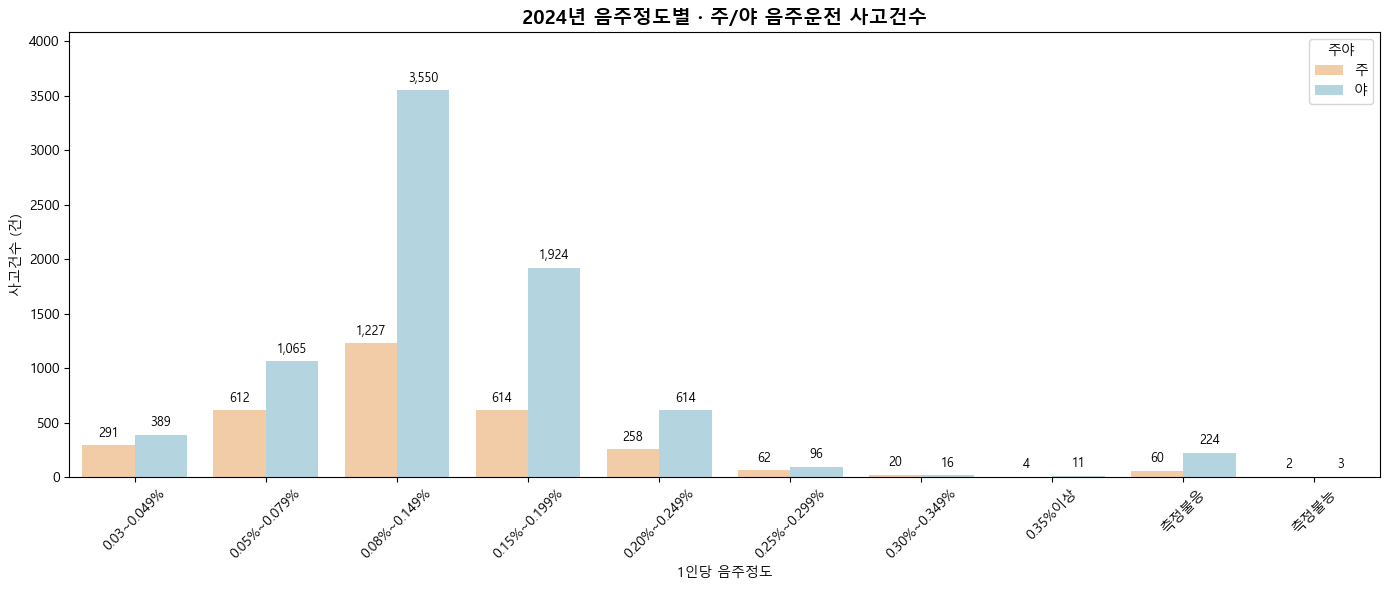

In [ ]:
fig, ax = plt.subplots(figsize=(14, 6))

palette = {"주": "#FFCC99", "야": "#ADD8E6"} # 색상 지정

sns.barplot(
    data=df,
    x="음주정도",
    y="사고건수",
    hue="주야",
    order=order,
    palette=palette,
    ax=ax
)

ax.set_ylim(0, df["사고건수"].max() * 1.15)  # 라벨 공간 확보 # 막대 길이의 1.15를 곱한 높이에 사고 발생 횟수를 기입 하겠다.

for p in ax.patches:
    h = p.get_height()
    if h > 0:
        ax.annotate(
            f"{int(h):,}",
            (p.get_x() + p.get_width()/2, h),
            ha="center", va="bottom",
            xytext=(0, 4), textcoords="offset points",
            fontsize=9,
            clip_on=False
        )

ax.set_title("2024년 음주정도별 · 주/야 음주운전 사고건수", fontsize=14, fontweight="bold")
ax.set_xlabel("1인당 음주정도")
ax.set_ylabel("사고건수 (건)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
drink_sum = (
    Drunk_driving_2024.groupby("1당음주정도별(2)", as_index=False)["사고건수 (건)"].sum()
)

drink_sum

,1당음주정도별(2),사고건수 (건)
0,0.03~0.049%,680
1,0.05%~0.079%,1677
2,0.08%~0.149%,4777
3,0.15%~0.199%,2538
4,0.20%~0.249%,872
5,0.25%~0.299%,158
6,0.30%~0.349%,36
7,0.35%이상,15
8,측정불능,5
9,측정불응,284


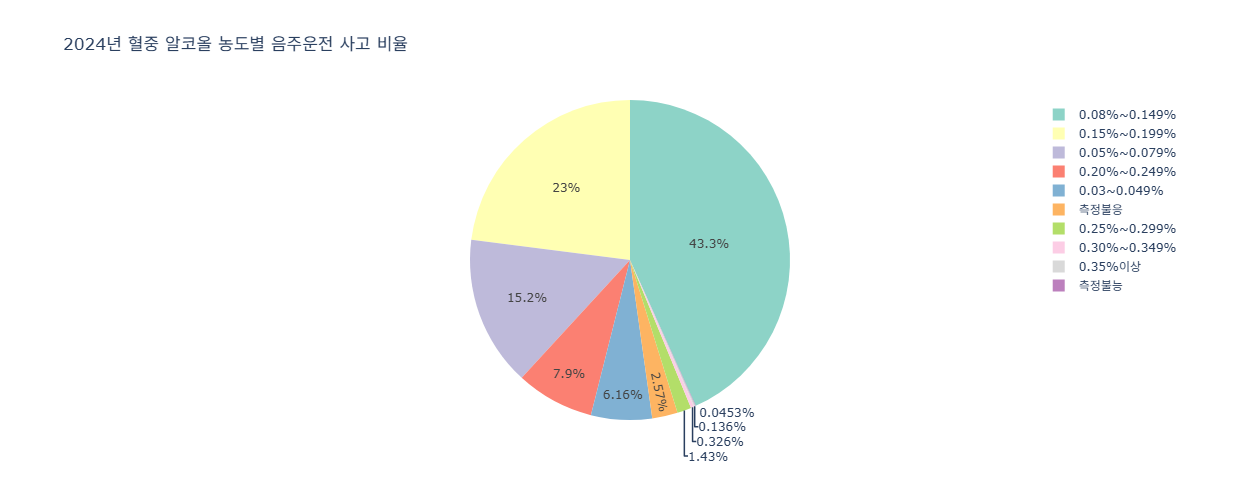

In [ ]:
# 파이그래프
import plotly.express as px

# ⬇️ 빈칸을 채워보세요
fig = px.pie(drink_sum, values="사고건수 (건)", names="1당음주정도별(2)", title='2024년 혈중 알코올 농도별 음주운전 사고 비율',
             color_discrete_sequence=px.colors.qualitative.Set3, # 색상 지정
             width=500, height=500) #크기 설정
fig.show()

## 2-2

In [ ]:

data_drive_obs = pd.merge(total_Drunk,korea_df,on='연도').set_index("연도")
data_drive_obs = pd.merge(data_drive_obs,soju_df,on='연도').set_index("연도")

#파일 저장
data_drive_obs.to_csv("./data/data_drive_obs.csv", index=False, encoding="utf-8-sig")
data_drive_obs.head()


,사고건수_총합,평균 술 소비량,소주 생활물가지수
연도,,,
2005,26473,9.0,69.342
2006,30185,9.2,69.539
2007,28662,9.3,71.995
2008,27009,9.5,73.526
2009,28394,8.9,78.530


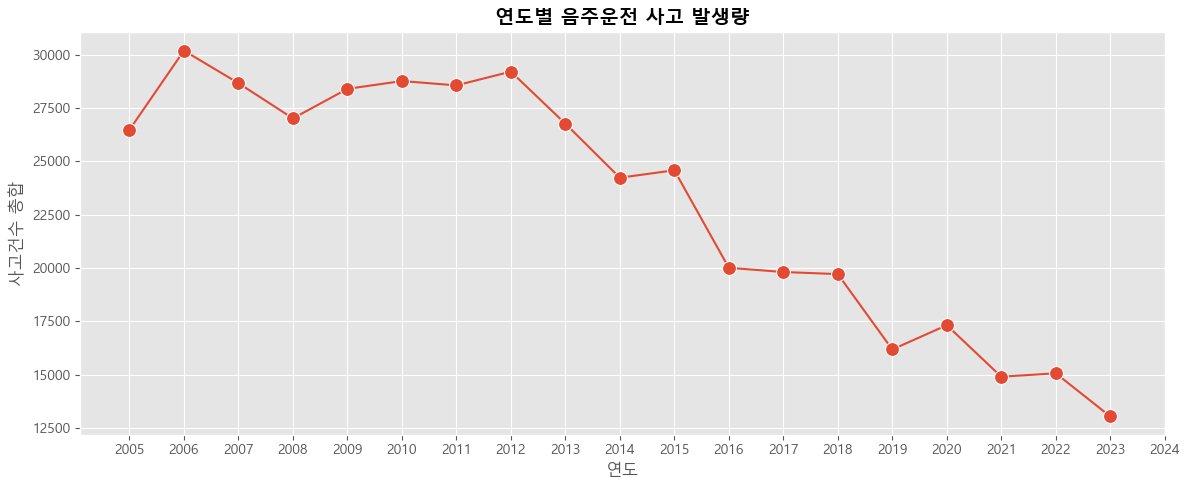

In [ ]:
# 연도별 음주운전 사고 발생량
plt.style.use("ggplot")
plt.figure(figsize = (12, 5))

sns.lineplot(data = data_drive_obs, x = "연도", y = "사고건수_총합", marker="o", markersize=10)

plt.title('연도별 음주운전 사고 발생량', size=14, fontweight="bold")
plt.xlabel('연도', size=12)
plt.ylabel('사고건수 총합')
plt.xticks(total_Drunk["연도"])
plt.tight_layout()


plt.show()

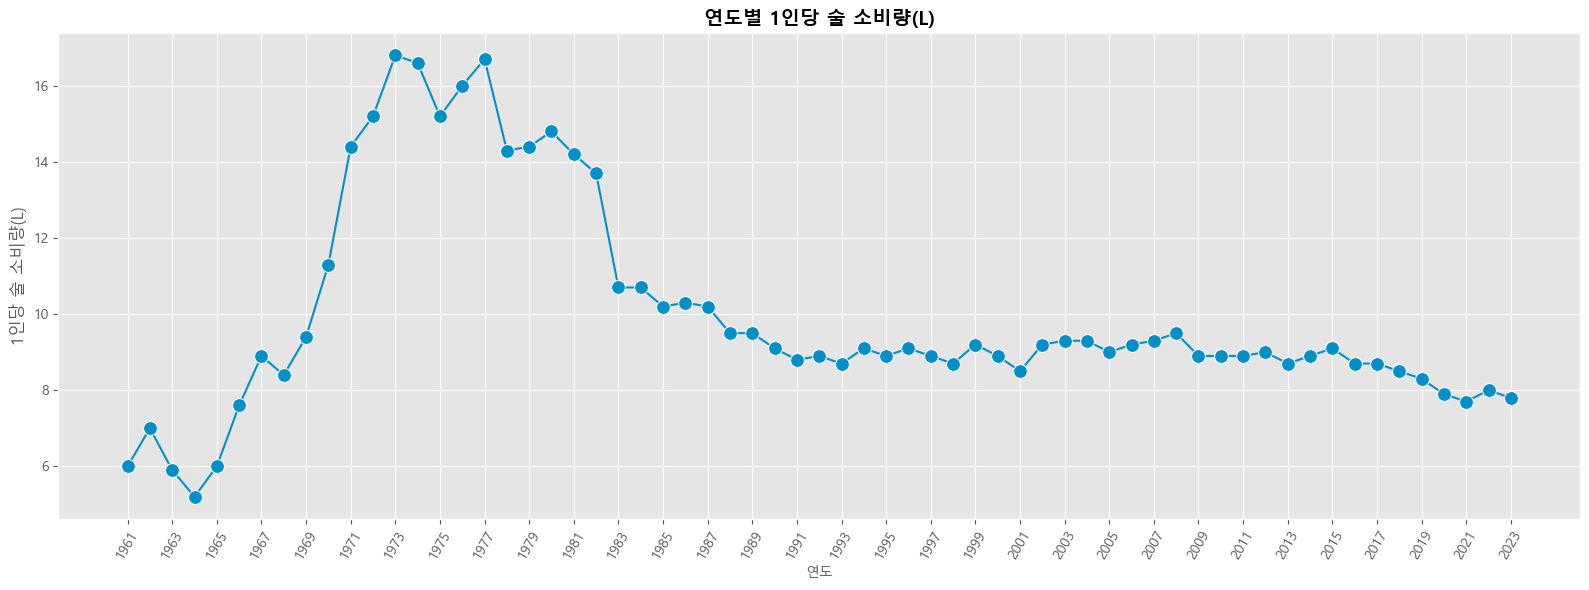

In [ ]:
# 연도별 1인당 술 소비량(L)(1961~2023)

plt.style.use("ggplot")
plt.figure(figsize = (16, 6))

sns.lineplot(data = korea_df, x = "연도", y = "평균 술 소비량", marker="o", markersize=10, color = "#0490c7")

plt.title('연도별 1인당 술 소비량(L)', size=14, fontweight="bold")
plt.xlabel('연도', size=10)
plt.ylabel('1인당 술 소비량(L)')
plt.xticks(korea_df["연도"][::2],rotation=60) # 2년 간격으로 칸을 나누고 표시
plt.tight_layout()


plt.show()

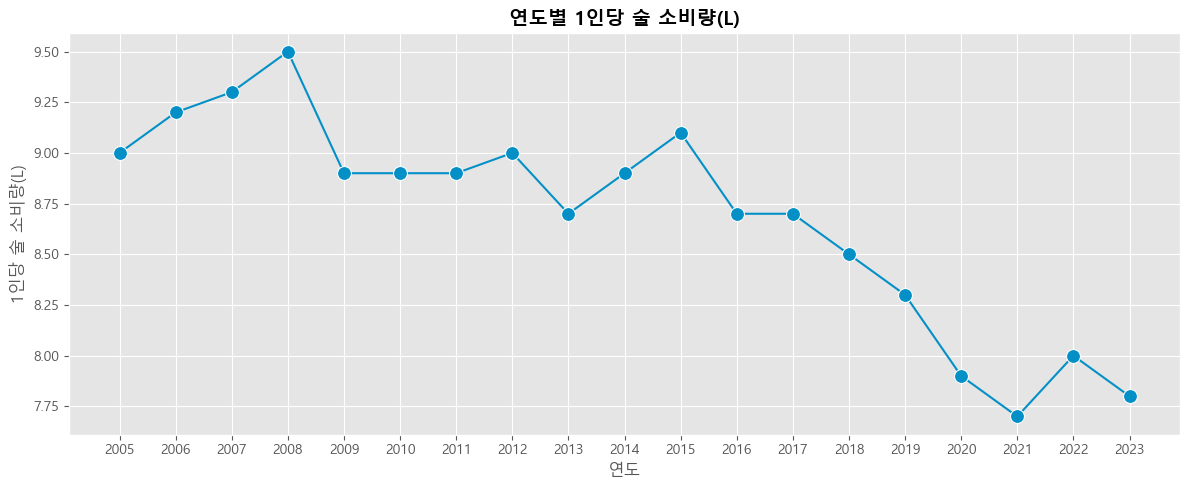

In [ ]:
# 연도별 1인당 술 소비량(L)(2005년 부터)
korea_df_from_2005 = korea_df.loc[korea_df["연도"] >= 2005]

plt.style.use("ggplot")
plt.figure(figsize = (12, 5))

sns.lineplot(data = data_drive_obs, x = "연도", y = "평균 술 소비량", marker="o", markersize=10, color = "#0490c7")

plt.title('연도별 1인당 술 소비량(L)', size=14, fontweight="bold")
plt.xlabel('연도', size=12)
plt.ylabel('1인당 술 소비량(L)')
plt.xticks(korea_df_from_2005["연도"])
plt.tight_layout()


plt.show()

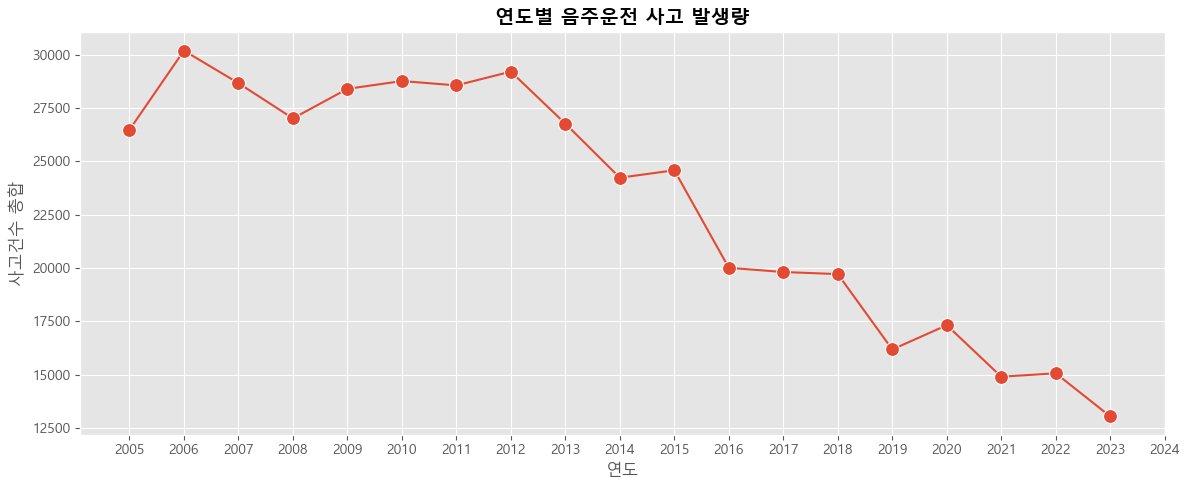

In [ ]:
# 연도별 음주운전 사고 발생량
plt.style.use("ggplot")
plt.figure(figsize = (12, 5))

sns.lineplot(data = data_drive_obs, x = "연도", y = "사고건수_총합", marker="o", markersize=10)

plt.title('연도별 음주운전 사고 발생량', size=14, fontweight="bold")
plt.xlabel('연도', size=12)
plt.ylabel('사고건수 총합')
plt.xticks(total_Drunk["연도"])
plt.tight_layout()


plt.show()

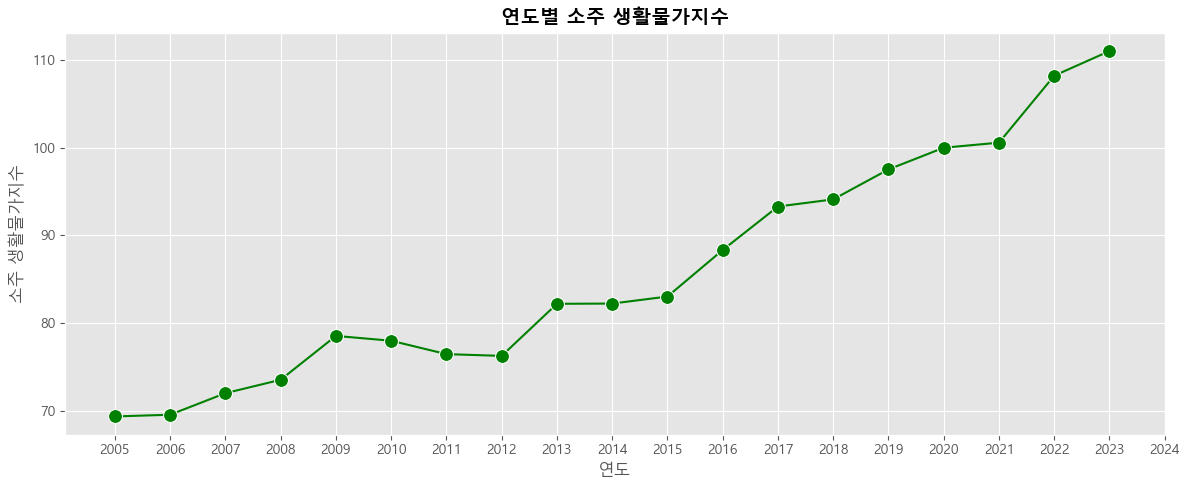

In [ ]:
# 연도별 음주운전 사고 발생량
plt.style.use("ggplot")
plt.figure(figsize = (12, 5))

sns.lineplot(data = data_drive_obs, x = "연도", y = "소주 생활물가지수", marker="o", markersize=10, color = 'green')

plt.title('연도별 소주 생활물가지수', size=14, fontweight="bold")
plt.xlabel('연도', size=12)
plt.ylabel('소주 생활물가지수')
plt.xticks(total_Drunk["연도"])
plt.tight_layout()


plt.show()

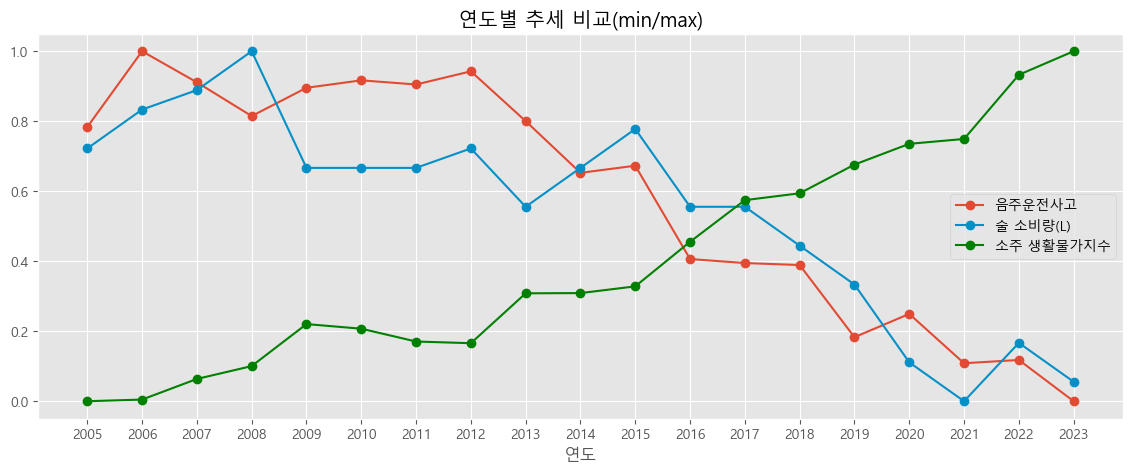

In [ ]:
norm_df = (data_drive_obs - data_drive_obs.min()) / \
(data_drive_obs.max() - data_drive_obs.min())

ax = norm_df["사고건수_총합"].plot(
    figsize=(14,5),
    marker='o',
    label="음주운전사고"
)

norm_df["평균 술 소비량"].plot(
    ax=ax,
    marker='o',
    label="술 소비량(L)",
    color = "#0490c7"
)

norm_df["소주 생활물가지수"].plot(
    ax=ax,
    marker='o',
    label="소주 생활물가지수",
    color = "green"
)

plt.xticks(norm_df.index)
plt.title("연도별 추세 비교(min/max)")
plt.legend()
plt.show()

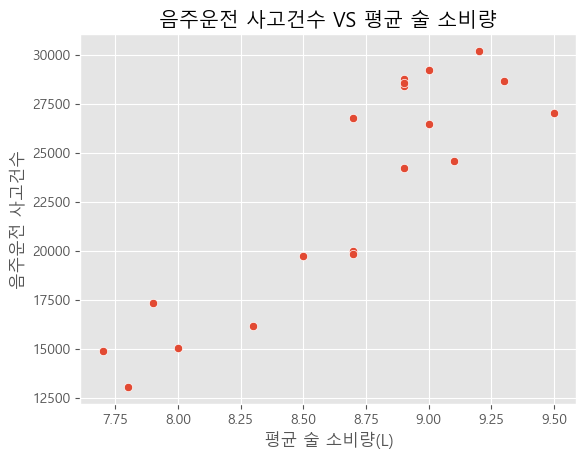

In [ ]:
# 사고건수와 평균 술 소비량의 산점도
sns.scatterplot(data = data_drive_obs, x= '평균 술 소비량', y='사고건수_총합')
plt.title("음주운전 사고건수 VS 평균 술 소비량")

plt.xlabel("평균 술 소비량(L)")
plt.ylabel("음주운전 사고건수")

plt.show()

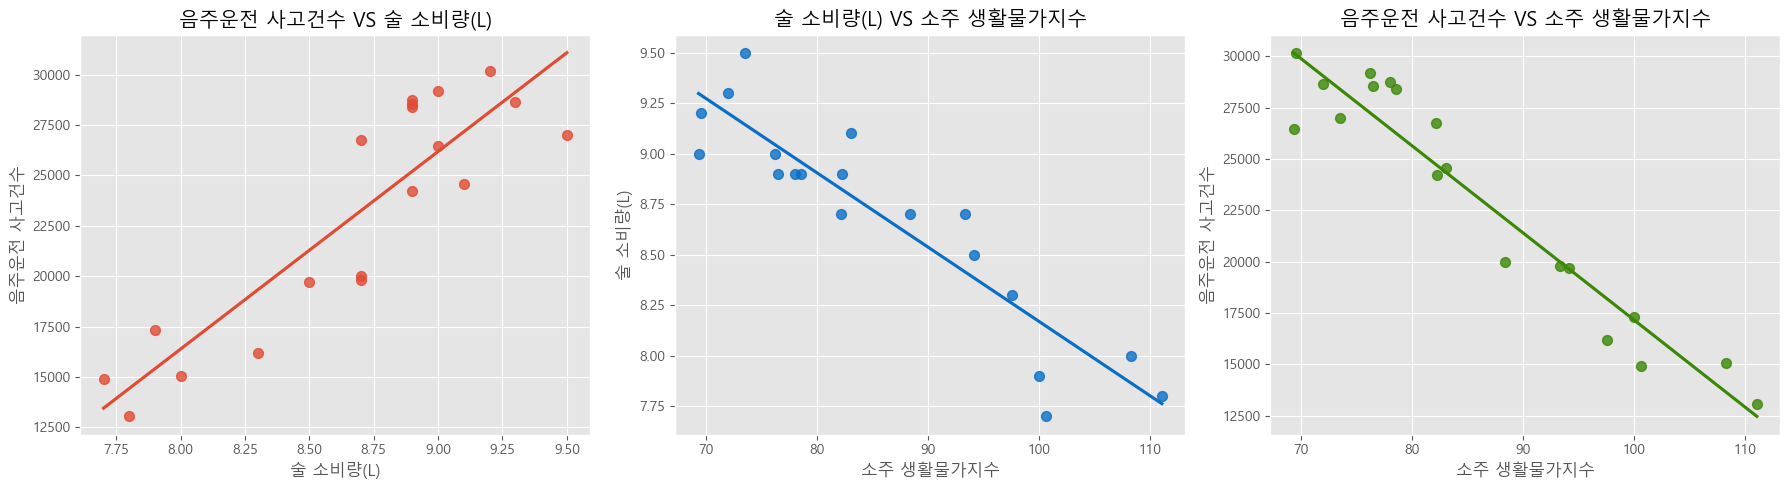

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# -----------------------------
# 1️. 평균 술 소비량 vs 사고건수
# -----------------------------
sns.regplot(
    data=data_drive_obs,
    x='평균 술 소비량',
    y='사고건수_총합',
    ci=None,
    scatter_kws={"s": 50},
    ax=axes[0]
)
axes[0].set_title("음주운전 사고건수 VS 술 소비량(L)")
axes[0].set_xlabel("술 소비량(L)")
axes[0].set_ylabel("음주운전 사고건수")
axes[0].grid(True)

# -----------------------------
# 2️. 소주 생활물가지수 vs 평균 술 소비량
# -----------------------------
sns.regplot(
    data=data_drive_obs,
    x='소주 생활물가지수',
    y='평균 술 소비량',
    ci=None,
    scatter_kws={"s": 50},
    color="#0a6ec6",
    ax=axes[1]
)
axes[1].set_title("술 소비량(L) VS 소주 생활물가지수")
axes[1].set_xlabel("소주 생활물가지수")
axes[1].set_ylabel("술 소비량(L)")
axes[1].grid(True)

# -----------------------------
# 3️. 사고건수 vs 소주 생활물가지수
# -----------------------------
sns.regplot(
    data=data_drive_obs,
    x='소주 생활물가지수',
    y='사고건수_총합',
    ci=None,
    scatter_kws={"s": 50},
    color="#3c8707",
    ax=axes[2]
)
axes[2].set_title("음주운전 사고건수 VS 소주 생활물가지수")
axes[2].set_xlabel("소주 생활물가지수")
axes[2].set_ylabel("음주운전 사고건수")
axes[2].grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# 상관계수
corr_df = data_drive_obs.corr()
corr_df

,사고건수_총합,평균 술 소비량,소주 생활물가지수
사고건수_총합,1.000000,0.886207,-0.956800
평균 술 소비량,0.886207,1.000000,-0.917087
소주 생활물가지수,-0.956800,-0.917087,1.000000


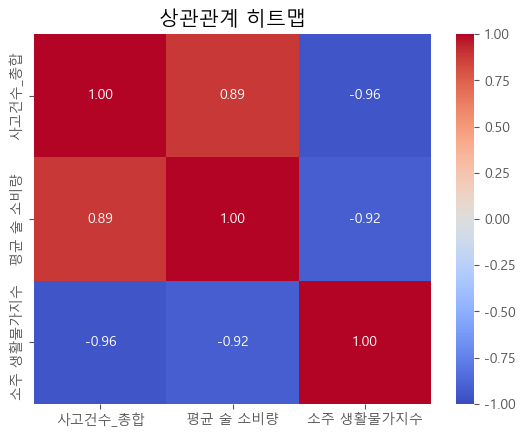

In [ ]:
# 상관관계 히트 맵
plt.rcParams["axes.unicode_minus"] = False

sns.heatmap(corr_df, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('상관관계 히트맵')
plt.show()